## 1. Setup

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

try:
    import cv2
except ImportError:
    !pip install -q opencv-python-headless
    import cv2

print("OpenCV version:", cv2.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 24.1 MB/s eta 0:00:00
OpenCV version: 5.0.0


In [3]:
# ---- Paths. Only change BASE if your Drive shortcut is named differently ----
BASE           = "/content/drive/MyDrive/Group_AIML"
INPUT_DIR      = f"{BASE}/Member 06_IT25103274/Outputs"   # channel-checked images (Member 6)
LABELS_DIR     = f"{BASE}/Member 02_IT25103229/Outputs"   # labels (Member 2)
OUTPUT_DIR     = f"{BASE}/Member 07/Outputs"
EDA_DIR        = f"{BASE}/Member 07/EDA"
LOCAL_SAVE_DIR = "/content/local_outputs"

SPLITS = ["train", "validation"]
IMG_SIZE = 224

# ---- Enhancement settings: these are the numbers you defend in the viva ----
CONTRAST_THRESHOLD = 40.0     # RMS contrast (std of grayscale, 0-255). Below this = low contrast
NOISE_THRESHOLD    = 5.0      # estimated noise sigma. Above this = noisy
CLAHE_CLIP_LIMIT   = 2.0      # higher = stronger contrast boost, but amplifies noise
CLAHE_TILE_GRID    = (8, 8)   # local tiles, so enhancement is adaptive not global
APPLY_TO_ALL       = False    # False = targeted (recommended). True = enhance every image
SAVE_DTYPE         = "float32"  # switch to "float16" if you run out of Drive space

In [4]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)
os.makedirs(LOCAL_SAVE_DIR, exist_ok=True)

print("INPUT_DIR exists:", os.path.exists(INPUT_DIR))
print("Contents of INPUT_DIR:", os.listdir(INPUT_DIR) if os.path.exists(INPUT_DIR) else "NOT FOUND")
print()
print("LABELS_DIR exists:", os.path.exists(LABELS_DIR))
print("Contents of LABELS_DIR:", os.listdir(LABELS_DIR) if os.path.exists(LABELS_DIR) else "NOT FOUND")

INPUT_DIR exists: True
Contents of INPUT_DIR: ['train_channel_checked_images.npy', 'train_channel_manifest.csv', 'validation_channel_checked_images.npy', 'validation_channel_manifest.csv']

LABELS_DIR exists: True
Contents of LABELS_DIR: ['validation_normalized_images.npy', 'train_normalized_images.npy', 'train_labels.npy', 'train_filepaths.npy', 'validation_labels.npy', 'validation_filepaths.npy']


In [5]:
def to_uint8(img_float):
    """Our arrays are float 0-1. OpenCV's CLAHE and filters need uint8 0-255."""
    return np.clip(img_float * 255.0, 0, 255).astype(np.uint8)


def estimate_noise_sigma(gray_u8):
    """Immerkaer fast noise variance estimation."""
    H, W = gray_u8.shape
    kernel = np.array([[1, -2, 1],
                       [-2, 4, -2],
                       [1, -2, 1]], dtype=np.float32)
    conv = cv2.filter2D(gray_u8.astype(np.float32), -1, kernel)
    sigma = np.sum(np.abs(conv))
    sigma = sigma * np.sqrt(0.5 * np.pi) / (6.0 * (W - 2) * (H - 2))
    return float(sigma)


def image_metrics(img_float):
    u8 = to_uint8(img_float)
    gray = cv2.cvtColor(u8, cv2.COLOR_RGB2GRAY)
    return {
        "mean_brightness": float(gray.mean()),
        "rms_contrast":    float(gray.std()),
        "sharpness":       float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "noise_sigma":     estimate_noise_sigma(gray),
    }

## 3. Pass 1 - audit every image

In [6]:
metrics_rows = []

for split in SPLITS:
    array_path    = os.path.join(INPUT_DIR, f"{split}_channel_checked_images.npy")
    manifest_path = os.path.join(INPUT_DIR, f"{split}_channel_manifest.csv")

    if not os.path.exists(array_path):
        print(f"WARNING: {array_path} not found - skipping {split}")
        continue

    images = np.load(array_path, mmap_mode="r")   # memory-mapped: RAM stays small
    N = images.shape[0]

    if os.path.exists(manifest_path):
        classes = pd.read_csv(manifest_path)["class"].values
    else:
        classes = np.array([""] * N)

    print(f"\n{split}: {N} images, shape {images.shape}, dtype {images.dtype}")

    for i in tqdm(range(N), desc=f"Auditing {split}"):
        m = image_metrics(np.asarray(images[i], dtype=np.float32))
        m["split"] = split
        m["index"] = i
        m["class"] = classes[i] if i < len(classes) else ""
        metrics_rows.append(m)

    del images

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(os.path.join(LOCAL_SAVE_DIR, "quality_metrics_audit.csv"), index=False)
print("\nAudit complete.")
metrics_df.head()


train: 11662 images, shape (11662, 224, 224, 3), dtype float32


Auditing train: 100%|██████████| 11662/11662 [01:02<00:00, 185.50it/s]



validation: 2012 images, shape (2012, 224, 224, 3), dtype float32


Auditing validation: 100%|██████████| 2012/2012 [00:08<00:00, 223.94it/s]



Audit complete.


,mean_brightness,rms_contrast,sharpness,noise_sigma,split,index,class
0,128.091916,53.108098,7736.387400,13.094832,train,0,Wilt
1,125.367267,53.301856,4902.535824,8.301824,train,1,Wilt
2,122.700933,37.363414,2262.085599,5.461663,train,2,Wilt
3,129.709423,54.631664,4869.860511,8.792759,train,3,Wilt
4,150.060507,64.071965,12562.419138,16.440780,train,4,Wilt


## 4. EDA - metric distributions, Bad Images

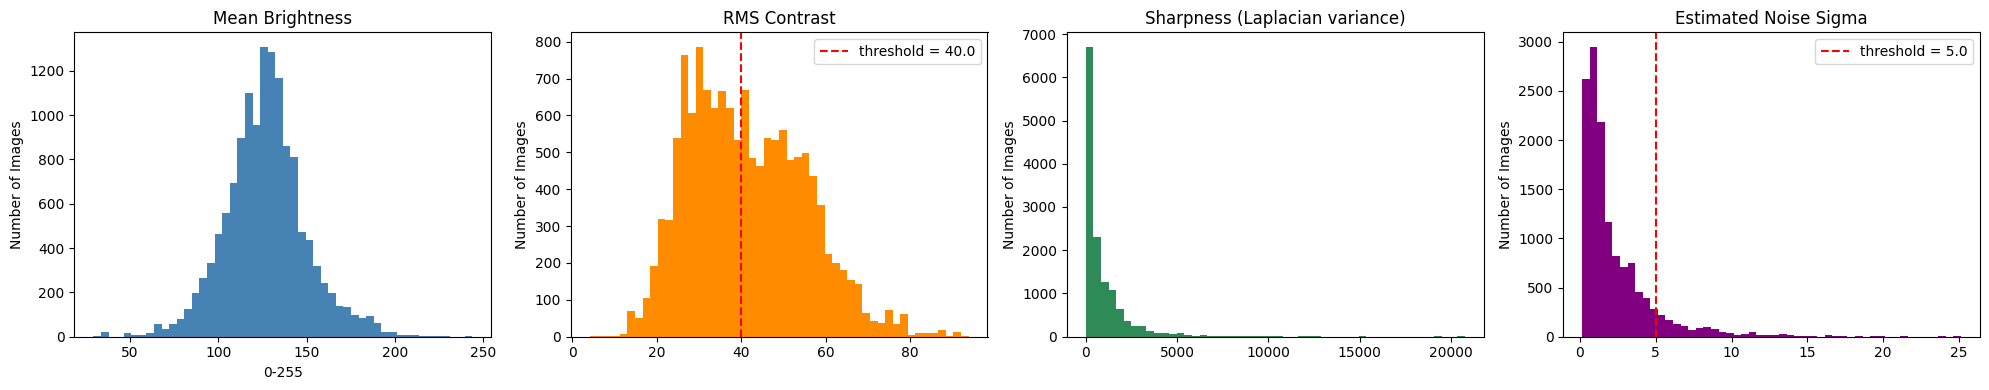

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].hist(metrics_df["mean_brightness"], bins=50, color="steelblue")
axes[0].set_title("Mean Brightness")
axes[0].set_xlabel("0-255")

axes[1].hist(metrics_df["rms_contrast"], bins=50, color="darkorange")
axes[1].axvline(CONTRAST_THRESHOLD, color="red", linestyle="--",
                label=f"threshold = {CONTRAST_THRESHOLD}")
axes[1].set_title("RMS Contrast")
axes[1].legend()

axes[2].hist(metrics_df["sharpness"], bins=50, color="seagreen")
axes[2].set_title("Sharpness (Laplacian variance)")

axes[3].hist(metrics_df["noise_sigma"], bins=50, color="purple")
axes[3].axvline(NOISE_THRESHOLD, color="red", linestyle="--",
                label=f"threshold = {NOISE_THRESHOLD}")
axes[3].set_title("Estimated Noise Sigma")
axes[3].legend()

for ax in axes:
    ax.set_ylabel("Number of Images")

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "quality_metrics_distributions.png"), dpi=120)
plt.show()

In [8]:
# How many images are flagged? These are the numbers that justify doing anything at all.
low_contrast = metrics_df["rms_contrast"] < CONTRAST_THRESHOLD
noisy        = metrics_df["noise_sigma"] > NOISE_THRESHOLD

total = len(metrics_df)
print(f"Total images audited      : {total}")
print(f"Low contrast (< {CONTRAST_THRESHOLD})    : {low_contrast.sum()}  ({100*low_contrast.mean():.1f}%)")
print(f"Noisy (sigma > {NOISE_THRESHOLD})         : {noisy.sum()}  ({100*noisy.mean():.1f}%)")
print(f"Needs some enhancement    : {(low_contrast | noisy).sum()}  ({100*(low_contrast | noisy).mean():.1f}%)")
print()
print("Per-split breakdown:")
print(metrics_df.assign(low_contrast=low_contrast, noisy=noisy)
                .groupby("split")[["low_contrast", "noisy"]].sum())
print()
print("Classes most affected by low contrast (top 10):")
print(metrics_df[low_contrast]["class"].value_counts().head(10))

Total images audited      : 13674
Low contrast (< 40.0)    : 6882  (50.3%)
Noisy (sigma > 5.0)         : 1421  (10.4%)
Needs some enhancement    : 8011  (58.6%)

Per-split breakdown:
            low_contrast  noisy
split                          
train               6180    947
validation           702    474

Classes most affected by low contrast (top 10):
class
Brownspot                     1353
Tungro                        1292
Healthy Maize                 1121
Rice Blast                     515
Mosaic sugarcane               376
Gray_Leaf_Spot                 371
Healthy cotton                 367
Sugarcane Healthy              301
Becterial Blight in Rice       292
bacterial_blight in Cotton     219
Name: count, dtype: int64


In [9]:
clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID)


def enhance_contrast(img_float):
    """CLAHE applied to the L (lightness) channel only, so colour is preserved."""
    u8 = to_uint8(img_float)
    lab = cv2.cvtColor(u8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = clahe.apply(l)
    out = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
    return out.astype(np.float32) / 255.0


def denoise(img_float):
    """Edge-preserving denoise. Light settings so lesion edges survive."""
    u8 = to_uint8(img_float)
    out = cv2.bilateralFilter(u8, d=5, sigmaColor=40, sigmaSpace=5)
    return out.astype(np.float32) / 255.0

## 6. Pass 2 - apply enhancement and save

In [10]:
for split in SPLITS:
    array_path = os.path.join(INPUT_DIR, f"{split}_channel_checked_images.npy")
    if not os.path.exists(array_path):
        print(f"WARNING: skipping {split}")
        continue

    images = np.load(array_path, mmap_mode="r")
    N = images.shape[0]

    sub = metrics_df[metrics_df["split"] == split].sort_values("index").reset_index(drop=True)
    contrast_vals = sub["rms_contrast"].to_numpy()
    noise_vals    = sub["noise_sigma"].to_numpy()
    class_vals    = sub["class"].to_numpy()

    # Write straight to disk so RAM never holds the whole array
    out_path = os.path.join(LOCAL_SAVE_DIR, f"{split}_quality_enhanced_images.npy")
    out = np.lib.format.open_memmap(
        out_path, mode="w+", dtype=SAVE_DTYPE, shape=(N, IMG_SIZE, IMG_SIZE, 3)
    )

    records = []
    print(f"\n{split}: enhancing {N} images")

    for i in tqdm(range(N), desc=f"Enhancing {split}"):
        img = np.asarray(images[i], dtype=np.float32)

        is_low_contrast = bool(contrast_vals[i] < CONTRAST_THRESHOLD)
        is_noisy        = bool(noise_vals[i] > NOISE_THRESHOLD)

        did_clahe = False
        did_denoise = False

        if APPLY_TO_ALL or is_low_contrast:
            img = enhance_contrast(img)
            did_clahe = True
        if is_noisy:
            img = denoise(img)
            did_denoise = True

        out[i] = img.astype(SAVE_DTYPE)

        gray_after = cv2.cvtColor(to_uint8(img), cv2.COLOR_RGB2GRAY)
        records.append({
            "split": split,
            "index": i,
            "class": class_vals[i],
            "rms_contrast_before": float(contrast_vals[i]),
            "rms_contrast_after":  float(gray_after.std()),
            "noise_sigma_before":  float(noise_vals[i]),
            "clahe_applied": did_clahe,
            "denoised": did_denoise,
            "was_enhanced": did_clahe or did_denoise,
        })

    out.flush()
    del out
    del images

    manifest_df = pd.DataFrame(records)
    manifest_local = os.path.join(LOCAL_SAVE_DIR, f"{split}_quality_manifest.csv")
    manifest_df.to_csv(manifest_local, index=False)

    # ---- Copy this split's files to Drive ----
    for fname in [f"{split}_quality_enhanced_images.npy", f"{split}_quality_manifest.csv"]:
        print(f"Copying {fname} to Drive (this can take a few minutes for the .npy)...")
        shutil.copy(os.path.join(LOCAL_SAVE_DIR, fname), os.path.join(OUTPUT_DIR, fname))
        print(f"Done: {fname}")

    print(f"Saved {split} outputs to {OUTPUT_DIR}")


train: enhancing 11662 images


Enhancing train: 100%|██████████| 11662/11662 [00:55<00:00, 209.73it/s]


Copying train_quality_enhanced_images.npy to Drive (this can take a few minutes for the .npy)...
Done: train_quality_enhanced_images.npy
Copying train_quality_manifest.csv to Drive (this can take a few minutes for the .npy)...
Done: train_quality_manifest.csv
Saved train outputs to /content/drive/MyDrive/Group_AIML/Member 07/Outputs

validation: enhancing 2012 images


Enhancing validation: 100%|██████████| 2012/2012 [00:48<00:00, 41.72it/s]


Copying validation_quality_enhanced_images.npy to Drive (this can take a few minutes for the .npy)...
Done: validation_quality_enhanced_images.npy
Copying validation_quality_manifest.csv to Drive (this can take a few minutes for the .npy)...
Done: validation_quality_manifest.csv
Saved validation outputs to /content/drive/MyDrive/Group_AIML/Member 07/Outputs


## 7. EDA - before vs after image comparison

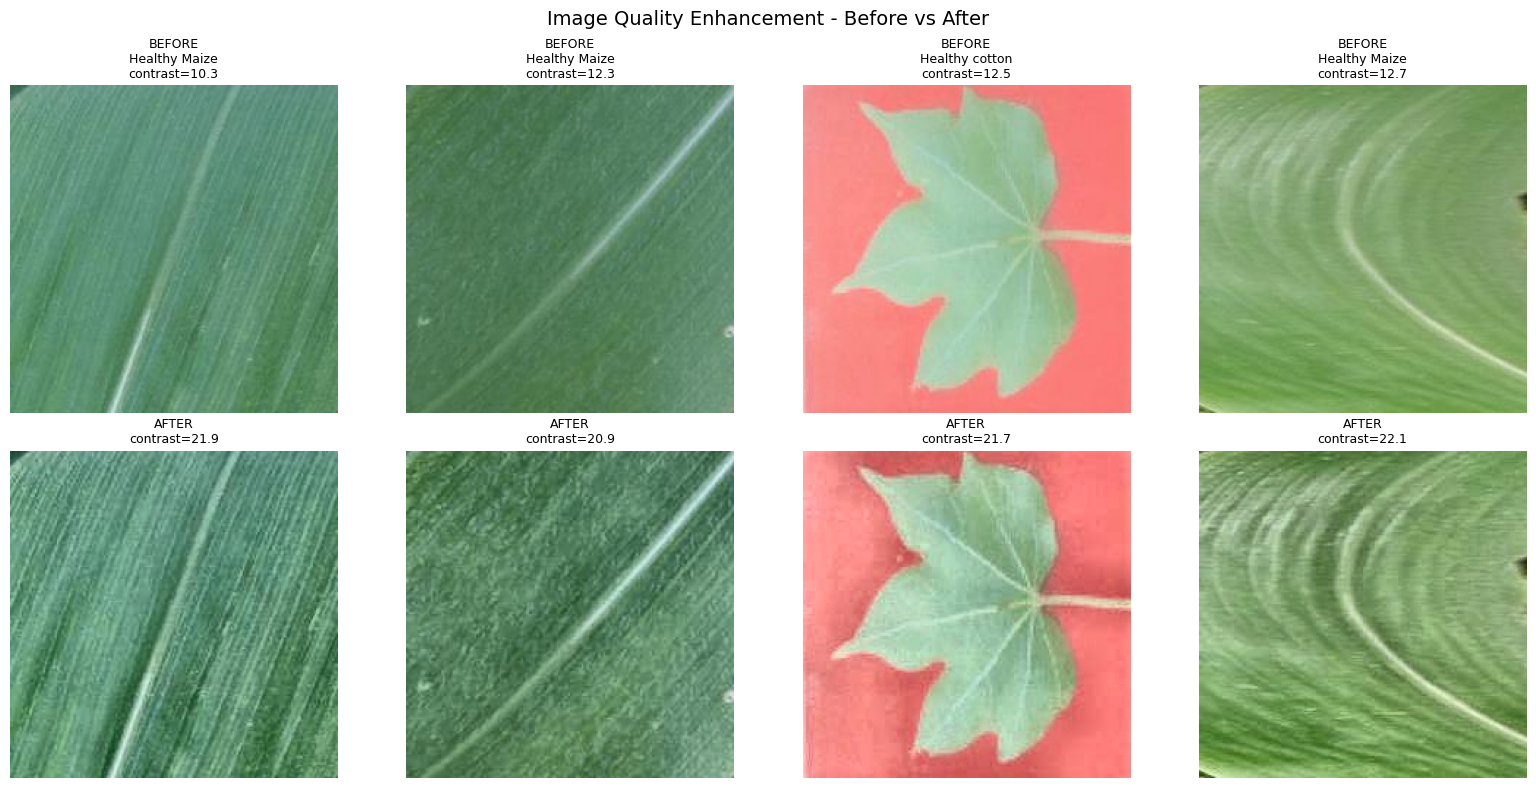

In [11]:
# Pick a few of the worst-contrast TRAIN images to show the effect clearly
split = "train"
orig = np.load(os.path.join(INPUT_DIR, f"{split}_channel_checked_images.npy"), mmap_mode="r")
enh  = np.load(os.path.join(LOCAL_SAVE_DIR, f"{split}_quality_enhanced_images.npy"), mmap_mode="r")

man = pd.read_csv(os.path.join(LOCAL_SAVE_DIR, f"{split}_quality_manifest.csv"))
worst = man[man["was_enhanced"]].nsmallest(4, "rms_contrast_before")

if len(worst) == 0:
    print("No images were flagged - showing 4 random samples instead.")
    worst = man.sample(4, random_state=42)

n = len(worst)
fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
if n == 1:
    axes = axes.reshape(2, 1)

for col, (_, row) in enumerate(worst.iterrows()):
    i = int(row["index"])
    axes[0, col].imshow(np.clip(np.asarray(orig[i], dtype=np.float32), 0, 1))
    axes[0, col].set_title(f"BEFORE\n{row['class']}\ncontrast={row['rms_contrast_before']:.1f}", fontsize=9)
    axes[0, col].axis("off")

    axes[1, col].imshow(np.clip(np.asarray(enh[i], dtype=np.float32), 0, 1))
    axes[1, col].set_title(f"AFTER\ncontrast={row['rms_contrast_after']:.1f}", fontsize=9)
    axes[1, col].axis("off")

plt.suptitle("Image Quality Enhancement - Before vs After", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "enhancement_before_after_samples.png"), dpi=120)
plt.show()

del orig, enh

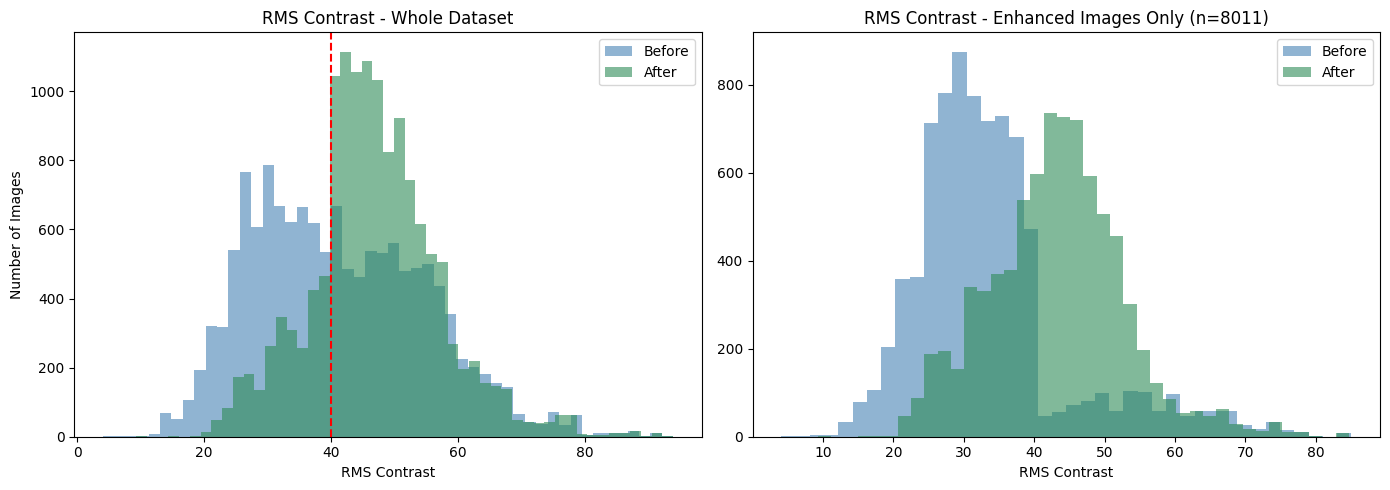

Mean contrast of enhanced images: 33.70 -> 43.24


In [12]:
# Contrast distribution: before vs after (only over the images we actually touched)
all_man = pd.concat([
    pd.read_csv(os.path.join(LOCAL_SAVE_DIR, f"{s}_quality_manifest.csv"))
    for s in SPLITS
    if os.path.exists(os.path.join(LOCAL_SAVE_DIR, f"{s}_quality_manifest.csv"))
])

touched = all_man[all_man["was_enhanced"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(all_man["rms_contrast_before"], bins=50, alpha=0.6, label="Before", color="steelblue")
axes[0].hist(all_man["rms_contrast_after"],  bins=50, alpha=0.6, label="After",  color="seagreen")
axes[0].axvline(CONTRAST_THRESHOLD, color="red", linestyle="--")
axes[0].set_title("RMS Contrast - Whole Dataset")
axes[0].set_xlabel("RMS Contrast")
axes[0].set_ylabel("Number of Images")
axes[0].legend()

if len(touched) > 0:
    axes[1].hist(touched["rms_contrast_before"], bins=40, alpha=0.6, label="Before", color="steelblue")
    axes[1].hist(touched["rms_contrast_after"],  bins=40, alpha=0.6, label="After",  color="seagreen")
    axes[1].set_title(f"RMS Contrast - Enhanced Images Only (n={len(touched)})")
    axes[1].set_xlabel("RMS Contrast")
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "No images were enhanced", ha="center")

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "contrast_before_after_hist.png"), dpi=120)
plt.show()

if len(touched) > 0:
    print(f"Mean contrast of enhanced images: {touched['rms_contrast_before'].mean():.2f} -> "
          f"{touched['rms_contrast_after'].mean():.2f}")

## 8. Carry labels forward and print a final summary

In [13]:
# Copy the label arrays into my Outputs folder so the final preprocessed set is self-contained
for split in SPLITS:
    src = os.path.join(LABELS_DIR, f"{split}_labels.npy")
    if os.path.exists(src):
        shutil.copy(src, os.path.join(OUTPUT_DIR, f"{split}_labels.npy"))
        print(f"Copied {split}_labels.npy")
    else:
        print(f"WARNING: {src} not found")

# Also keep the full audit CSV as evidence of the investigation
shutil.copy(os.path.join(LOCAL_SAVE_DIR, "quality_metrics_audit.csv"),
            os.path.join(OUTPUT_DIR, "quality_metrics_audit.csv"))

print("\n" + "=" * 60)
print("MEMBER 07 - IMAGE QUALITY ENHANCEMENT: COMPLETE")
print("=" * 60)
print(f"Images audited        : {len(metrics_df)}")
print(f"Images enhanced       : {int(all_man['was_enhanced'].sum())}")
print(f"  - CLAHE applied     : {int(all_man['clahe_applied'].sum())}")
print(f"  - Denoised          : {int(all_man['denoised'].sum())}")
print(f"\nOutputs -> {OUTPUT_DIR}")
print(f"EDA charts -> {EDA_DIR}")
print(f"\nOutput array format: (N, {IMG_SIZE}, {IMG_SIZE}, 3), {SAVE_DTYPE}, range 0-1")
print("Same format as Member 6's input, so the pipeline contract is unchanged.")

Copied train_labels.npy
Copied validation_labels.npy

MEMBER 07 - IMAGE QUALITY ENHANCEMENT: COMPLETE
Images audited        : 13674
Images enhanced       : 8011
  - CLAHE applied     : 6882
  - Denoised          : 1421

Outputs -> /content/drive/MyDrive/Group_AIML/Member 07/Outputs
EDA charts -> /content/drive/MyDrive/Group_AIML/Member 07/EDA

Output array format: (N, 224, 224, 3), float32, range 0-1
Same format as Member 6's input, so the pipeline contract is unchanged.
